# Which planned blocks are likely to slip?

GrowthTracker users plan time blocks and later mark them done or skipped. This notebook builds and evaluates the model behind the app's *"Likely to slip: you often miss evening blocks"* label, and behind Plan my week leaving risky suggestions unticked.

1. The data, and why it's simulated
2. The model: logistic regression over the block's details and the person's shrunken skip rates
3. Evaluation the way the app is used: each block predicted only from blocks that ended a day earlier
4. Are the stated risks right? (calibration)
5. When to show a label
6. Alternatives, and limitations

It runs the same code as `uv run growthtracker-ml train`, which writes the model file the API loads. Model card: [`../SKIP_RISK_MODEL_CARD.md`](../SKIP_RISK_MODEL_CARD.md).

In [1]:
import numpy as np
import pandas as pd

from growthtracker_ml import report as base_report
from growthtracker_ml.skiprisk import pipeline, report, synth
from growthtracker_ml.skiprisk.evaluate import by_history, flag_quality, score
from growthtracker_ml.skiprisk.features import band_of
from growthtracker_ml.skiprisk.model import design

pd.set_option("display.precision", 3)
result = pipeline.run()
model, data, splits, counts = result.model, result.data, result.splits, result.counts
{name: f"{f['user_id'].nunique()} users, {len(f):,} blocks" for name, f in splits.items()}

{'train': '240 users, 18,281 blocks',
 'validation': '80 users, 6,069 blocks',
 'test': '80 users, 5,567 blocks'}

## 1. The data

There's no real dataset, so the model is developed on **simulated people** (`skiprisk/synth.py`). Each has their own overall reliability, their own good and bad times of day, and goals that slip more than others. Blocks run more risk when they're long, planned far ahead, on a crowded day, at the weekend, or straight after a miss.

Two things are deliberately different from the model: a miss makes the *very next* block likelier to slip, while the model only sees the share of misses among the last three; and each person's effects are fixed numbers the model can only estimate from a short, noisy record.

In [2]:
pd.DataFrame([synth.SkipConfig().as_dict()]).T.rename(columns={0: "value"})

,value
seed,29
n_users,400
base_logit_mean,-2.0
base_logit_sd,0.8
band_effects,"(0.55, 0.0, 0.1, 0.3, 0.7)"
personal_band_sd,0.5
goal_sd,0.4
weekend_effect,0.3
duration_effect,0.45
lead_effect,0.2


In [3]:
per_user = data.groupby("user_id")["missed"].mean()
print(f"Blocks missed overall: {data['missed'].mean():.0%}")
per_user.describe(percentiles=[0.1, 0.5, 0.9])[["10%", "50%", "90%"]].rename("share missed per person")

Blocks missed overall: 29%


10%    0.081
50%    0.250
90%    0.554
Name: share missed per person, dtype: float64

In [4]:
data.assign(band=[band_of(m) for m in data.start_minutes]).groupby("band")["missed"].agg(
    ["mean", "size"]
).loc[["early", "morning", "afternoon", "evening", "late"]].rename(
    columns={"mean": "missed", "size": "blocks"}
)

,missed,blocks
band,,
early,0.325,6573
morning,0.226,6007
afternoon,0.254,5989
evening,0.296,5752
late,0.356,5596


People differ far more than times of day do: the 10th-percentile person misses about 1 block in 12, the 90th more than half. That's why most of the model is about the person.

## 2. The model

$$P(\text{missed}) = \sigma(x \cdot \beta)$$

$x$ holds the block's own details (time-of-day band, weekend, log length, log days planned ahead, other blocks that day, goal link) and the person's history as **shrunken skip rates**:

- their overall rate, pulled towards the population rate by a beta prior fitted to training users (method of moments);
- their rate in this time band and for this goal, each pulled towards their overall rate;
- the share of their last three blocks that were missed.

With no history every rate equals the population's, so a new person gets the population answer; as their record grows, it takes over. Rates enter as log-odds, the natural scale for logistic regression. How hard to shrink the band and goal rates was chosen on validation users.

In [5]:
tuning = pd.Series(result.metrics["tuning"]["validationLogLoss"]).sort_values()
print(
    f"Chosen: band strength {model.shrinkage.band_strength:g}, goal strength {model.shrinkage.goal_strength:g}"
)
tuning.head(6).rename("validation log loss")

Chosen: band strength 50, goal strength 20


band 50, goal 20     0.526
band 100, goal 20    0.526
band 20, goal 20     0.526
band 50, goal 50     0.526
band 50, goal 10     0.526
band 100, goal 50    0.526
Name: validation log loss, dtype: float64

In [6]:
pd.Series(dict(zip(result.metrics["fit"]["coefficients"], model.coefficients, strict=True))).rename(
    "coefficient"
).to_frame()

,coefficient
intercept,-0.802
band_early,0.389
band_afternoon,0.172
band_evening,0.251
band_late,0.534
weekend,0.287
log_duration,0.339
log_lead_days,0.187
day_load,0.090
has_goal,-0.031


Every block effect points the way it was simulated (early and late bands, weekends, long blocks, blocks planned far ahead and crowded days all raise the risk), and the personal terms carry the most weight. The coefficients aren't comparable one-to-one with the simulator's numbers, because the personal effects reach the model through estimated rates rather than directly.

## 3. Evaluation, the way the app is used

Test users were never seen in training. Each block is predicted from that person's blocks that **ended at least a day before it started**, the same rule the API uses (people need time to tick a block off).

| | |
|---|---|
| **Everyone's miss rate** | one number for everyone |
| **Block details only** | the model without any personal history |
| **Your own miss rate** | the person's shrunken rate alone |
| **Model** | this project |
| **Noise floor** | the true probability from the simulator: the best any model could do |

Log loss and the Brier score reward honest probabilities; AUC measures how well risky blocks are ranked above safe ones; calibration error is the average gap between stated and observed rates.

In [7]:
scores = pd.DataFrame(result.metrics["test"]).T[["log_loss", "brier", "auc", "calibration_error"]]
scores.index = scores.index.map(report.LABELS)
scores

,log_loss,brier,auc,calibration_error
Everyone's miss rate,0.612,0.210,0.500,0.009
Your own miss rate,0.556,0.187,0.698,0.016
Block details only,0.606,0.208,0.574,0.018
Model,0.543,0.181,0.722,0.018
Noise floor (true probability),0.500,0.165,0.780,0.015


In [8]:
t = result.metrics["test"]
gain = (t["population_rate"]["log_loss"] - t["model"]["log_loss"]) / (
    t["population_rate"]["log_loss"] - t["oracle"]["log_loss"]
)
print(f"The model removes {gain:.0%} of the log loss that any model could remove.")

The model removes 62% of the log loss that any model could remove.


,population_rate,personal_rate,block_features_only,model,oracle,blocks
earlier resolved blocks,,,,,,
0,0.563,0.563,0.532,0.532,0.453,179
1-4,0.565,0.556,0.552,0.548,0.427,303
5-9,0.624,0.613,0.611,0.593,0.516,398
10-19,0.614,0.574,0.599,0.555,0.502,798
20-49,0.616,0.555,0.609,0.538,0.513,1990
50+,0.616,0.538,0.621,0.532,0.499,1899


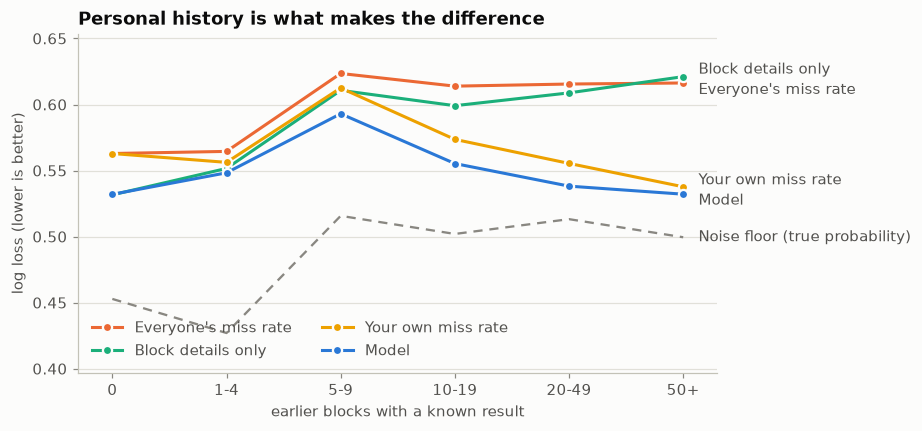

In [9]:
y = splits["test"]["missed"].to_numpy().astype(float)
n = counts["test"]["n"].to_numpy()
table = by_history(y, n, result.test_predictions)
fig = report.learning_curve(table)
_ = base_report.save(fig, "skip_risk_learning_curve")
table

Each column is a different mix of blocks (even the noise floor moves), so compare methods within a column rather than across. With no history, the block's details are all there is, and they help a little. The gap to the noise floor is mostly *who* the person is, which only their record can reveal: after 10 or so blocks with a known result the model is clearly ahead of the person's raw rate, because it combines that rate with the time of day, the goal and the block itself.

## 4. Are the stated risks right?

A label that says "likely" has to mean it. Blocks are grouped by predicted risk and compared with what happened.

,predicted,observed,blocks
0,0.065,0.078,579
1,0.153,0.179,1409
2,0.249,0.251,1354
3,0.346,0.332,931
4,0.445,0.459,562
5,0.545,0.577,416
6,0.644,0.725,233
7,0.736,0.720,75


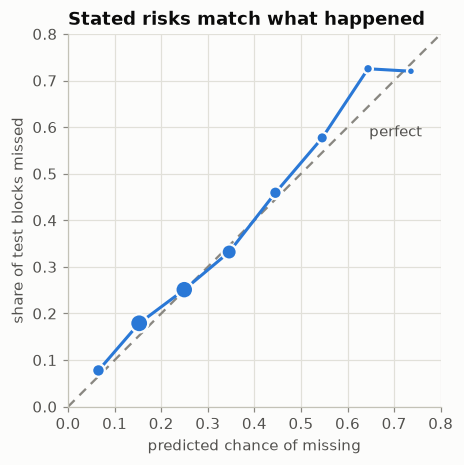

In [10]:
fig = report.calibration(result.metrics["reliability"])
_ = base_report.save(fig, "skip_risk_calibration")
pd.DataFrame(result.metrics["reliability"])

Across most of the range, stated and observed rates agree within a few points. At the top end the model is slightly cautious: blocks it gave about 64% were missed 72% of the time. Erring low suits a label meant to be trusted, so it's left as is rather than recalibrated.

## 5. When to show a label

Two rules, both set on validation users:

- **Enough history.** Labels appear once the person's own record outweighs the population rate in their overall rate: at $n \geq$ the prior's strength in blocks.
- **Mostly right.** A block is flagged at the lowest risk where at least 6 in 10 flagged validation blocks were really missed. A label that's wrong half the time teaches people to ignore it.

In [11]:
print(
    f"Prior strength {model.shrinkage.user_strength:.1f} blocks, so labels start at {model.min_history} blocks with a known result"
)
shown = n >= model.min_history
p = result.test_predictions["model"]
pd.DataFrame([flag_quality(y[shown], p[shown], round(t_, 2)) for t_ in np.arange(0.3, 0.75, 0.05)]).set_index(
    "threshold"
)

Prior strength 5.7 blocks, so labels start at 6 blocks with a known result


,flagged_share,precision,recall
threshold,,,
0.30,0.406,0.476,0.631
0.35,0.319,0.524,0.545
0.40,0.244,0.571,0.455
0.45,0.188,0.612,0.375
0.50,0.142,0.650,0.301
0.55,0.097,0.689,0.217
0.60,0.063,0.732,0.149
0.65,0.035,0.754,0.086
0.70,0.017,0.735,0.040


In [12]:
print(f"Chosen threshold: {model.threshold:.0%}")
result.metrics["flags"]

Chosen threshold: 50%


{'validation': {'threshold': 0.5,
  'flagged_share': 0.1132,
  'precision': 0.6437,
  'recall': 0.2597},
 'test': {'threshold': 0.5,
  'flagged_share': 0.1422,
  'precision': 0.6498,
  'recall': 0.301}}

At the chosen threshold, about 2 in 3 flagged blocks really were missed, and roughly 3 in 10 of all missed blocks were flagged in advance. That's deliberately cautious: the label catches the clearest cases rather than everything.

## 6. Alternatives that weren't chosen

**Gradient boosting** on the same inputs (the block's details and the raw history counts the shrunken rates are built from):

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier


def raw_inputs(name):
    X = design(splits[name], counts[name], model.shrinkage)[:, 1:10]
    c = counts[name][["n", "misses", "band_n", "band_misses", "goal_n", "goal_misses", "recent"]].to_numpy()
    return np.column_stack([X, c])


gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0)
gbm.fit(raw_inputs("train"), splits["train"]["missed"].astype(int))
p_gbm = gbm.predict_proba(raw_inputs("test"))[:, 1]
pd.DataFrame({"logistic model (shipped)": score(y, p), "gradient boosting": score(y, p_gbm)}).T

,log_loss,brier,auc,calibration_error,n
logistic model (shipped),0.543,0.181,0.722,0.018,5567.0
gradient boosting,0.548,0.183,0.713,0.018,5567.0


**Why the logistic model ships.** Gradient boosting has to learn from raw counts how much to trust a short record, which the shrunken rates already encode, so with the same information it does no better. The logistic model is 14 numbers in a JSON file, a few lines of TypeScript, well calibrated by construction, and its terms can be turned into plain reasons ("You often miss evening blocks").

## Limitations

- **Simulated data.** The block effects (bands, weekends, length, lead time, crowded days) are the simulator's assumptions until the model is retrained on real records. This is why labels wait for the person's own record.
- **Unticked blocks are unknown.** The app counts a block as missed only when marked skipped, and as kept when marked done or worked on with the focus timer. Someone who never marks skips will look more reliable than they are, so labels err towards silence.
- **The past is a guide, not a rule.** A new routine (a new job, a new term) changes everything; the model only adapts as new blocks are resolved, using the last 100.
- **No knowledge of the block's content**, the weather, or anything outside the app.